# 01 - EDA (train uniquement)

only for the train


this notebook answer the folowing question : how many lignes , how many pannes , how many double values do we have, the range of our variable , and a label audit

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(ROOT / "data" / "processed" / "train.csv")

FLAGS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
NUM = ["Air temperature [K]", "Process temperature [K]",
       "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
df.shape

(8000, 14)

## 1 rows et breakdowns



In [2]:
print("lignes   :", len(df))
print("positifs :", int(df["Machine failure"].sum()))
print("taux     :", round(df["Machine failure"].mean(), 4))
print(df["Type"].value_counts().to_dict())

lignes   : 8000
positifs : 271
taux     : 0.0339
{'L': 4800, 'M': 2397, 'H': 803}


## 2 missing and double values


In [3]:
print("valeurs manquantes :", int(df.isna().sum().sum()))
print("lignes dupliquées  :", int(df.duplicated().sum()))
print("Product ID dupliqués:", int(df["Product ID"].duplicated().sum()))

valeurs manquantes : 0
lignes dupliquées  : 0
Product ID dupliqués: 0


## 3. Variables ranges


ranges help to validet input for the api. the ranges are mainly fixed by the documentation , but if not we statisticaly and logicaly range them ourselves

In [4]:
ranges = df[NUM].agg(["min", "max", "mean"]).round(2).T
ranges

,min,max,mean
Air temperature [K],295.3,304.5,300.01
Process temperature [K],305.8,313.8,310.01
Rotational speed [rpm],1192.0,2886.0,1539.11
Torque [Nm],3.8,76.6,39.93
Tool wear [min],0.0,253.0,108.02


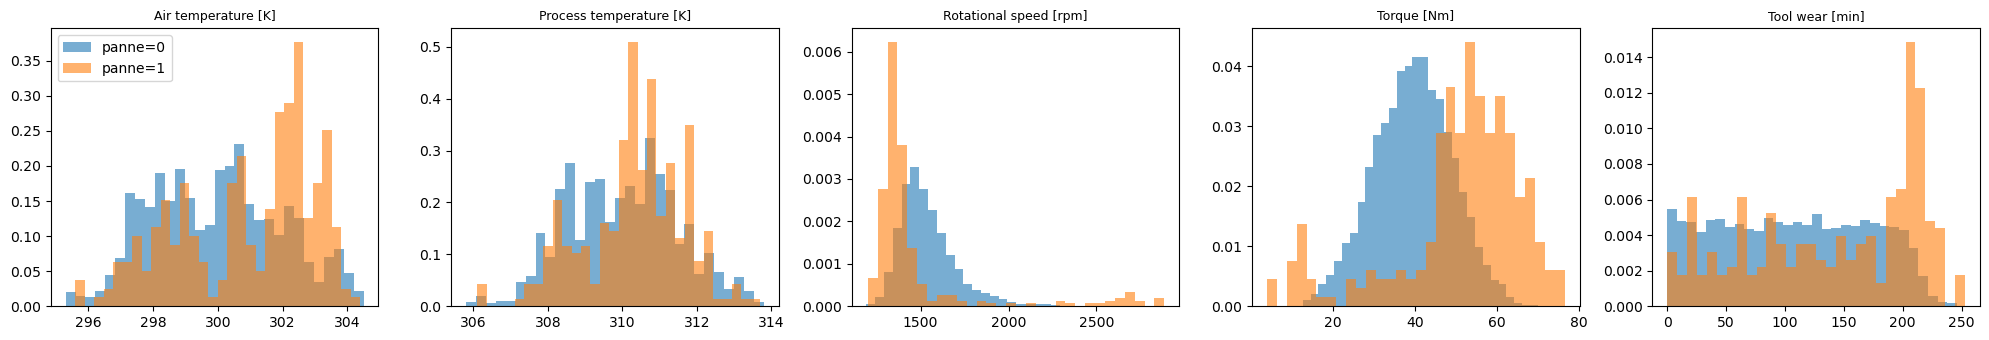

In [5]:
# Une seule figure, qui répond à : les variables séparent-elles les pannes ?
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, NUM):
    for label, g in df.groupby("Machine failure"):
        ax.hist(g[col], bins=30, alpha=0.6, density=True, label=f"panne={label}")
    ax.set_title(col, fontsize=9)
axes[0].legend()
plt.tight_layout()
plt.show()

Bornes **proposées** pour l'API (proposition, à valider avec Rayen) :

| Variable | Observé (train) | Borne API proposée |
|---|---|---|
| Air temperature [K] | 295.3 - 304.5 | 290 - 310 |
| Process temperature [K] | 305.8 - 313.8 | 300 - 320 |
| Rotational speed [rpm] | 1192 - 2886 | 1000 - 3000 |
| Torque [Nm] | 3.8 - 76.6 | 0 - 100 |
| Tool wear [min] | 0 - 253 | 0 - 300 |
| Type | H, L, M | H, L, M |

## 4. Label audit : flags de mode de panne vs `Machine failure`

In [6]:
any_flag = df[FLAGS].sum(axis=1) > 0
a = df[(df["Machine failure"] == 1) & (~any_flag)]   # panne sans aucun flag
b = df[(df["Machine failure"] == 0) & (any_flag)]    # flag actif sans panne

print("Machine failure = 1 sans aucun flag :", len(a))
print("Machine failure = 0 avec un flag    :", len(b))
print("Total incohérent :", len(a) + len(b), f"({(len(a) + len(b)) / len(df):.2%} du train)")
print("Part des positifs concernée :", f"{len(a) / df['Machine failure'].sum():.1%}")
print("Flags dans les 17 cas panne=0 :", b[FLAGS].sum().to_dict())
pd.concat([a, b])[["UDI", "Type", "Machine failure"] + FLAGS].sort_values("Machine failure")

Machine failure = 1 sans aucun flag : 9
Machine failure = 0 avec un flag    : 17
Total incohérent : 26 (0.33% du train)
Part des positifs concernée : 3.3%
Flags dans les 17 cas panne=0 : {'TWF': 0, 'HDF': 0, 'PWF': 0, 'OSF': 0, 'RNF': 17}


,UDI,Type,Machine failure,TWF,HDF,PWF,OSF,RNF
1649,5554,L,0,0,0,0,0,1
4471,7489,L,0,0,0,0,0,1
1903,3453,H,0,0,0,0,0,1
3327,2073,L,0,0,0,0,0,1
727,5490,L,0,0,0,0,0,1
1323,5510,L,0,0,0,0,0,1
544,5472,L,0,0,0,0,0,1
7323,5640,L,0,0,0,0,0,1
7012,1222,M,0,0,0,0,0,1
6946,6914,L,0,0,0,0,0,1
